# 02 Modelos lineales

In [ ]:
#librerias
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from bogoprice.features import construir_pipeline
from bogoprice.metrics import mdape, metricas_precio
from bogoprice.tracking import iniciar_mlflow, registrar_corrida

from bogoprice import config
from bogoprice.data_loader import cargar_train_test
from bogoprice.features import construir_features, filtrar_localidades, localidades_habilitadas

train, test, limite_p99 = cargar_train_test()
train, test = construir_features(train), construir_features(test)
localidades = localidades_habilitadas(train)
train, test = filtrar_localidades(train, localidades), filtrar_localidades(test, localidades)

X_train, y_train = train[config.FEATURES], train[config.TARGET_LOG]
X_test, y_test_cop = test[config.FEATURES], test[config.TARGET]
print(f"P99 junio: ${limite_p99:,.0f} | train {X_train.shape} | test {X_test.shape}")
print("Localidades habilitadas:", localidades)

P99 junio: $1,330,087 | train (17749, 14) | test (17561, 14)
Localidades habilitadas: ['Barrios Unidos', 'Candelaria', 'Chapinero', 'Engativa', 'Fontibon', 'Santa Fe', 'Suba', 'Teusaquillo', 'Usaquen']


## Línea base: mediana por localidad × room_type

In [2]:
iniciar_mlflow('bogoprice-baseline')

claves = ['neighbourhood_cleansed', 'room_type']
medianas = train.groupby(claves)[config.TARGET].median().rename('pred')
pred = test[claves].join(medianas, on=claves)['pred'].fillna(train[config.TARGET].median())
m = metricas_precio(y_test_cop, pred)
registrar_corrida('manuel_mediana_localidad_tipo', {'modelo': 'mediana', 'agrupacion': '+'.join(claves)}, m)
m

🏃 View run manuel_mediana_localidad_tipo at: http://3.82.57.253:8050/#/experiments/1/runs/b279626adcc540dda71b173acf1e6eef
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/1


{'mdape': 29.525699642149384,
 'mae_cop': 76895.14891008484,
 'rmse_log': 0.5167758388444819}

## Ridge y ElasticNet

In [ ]:
#en MLflow
iniciar_mlflow('bogoprice-lineales')

resultados = []
pipelines = {}
for nombre, modelo, params in [
    *[(f'manuel_ridge_a{a}', Ridge(alpha=a), {'modelo': 'Ridge', 'alpha': a}) for a in [0.1, 1, 10]],
    *[(f'manuel_enet_a{a}', ElasticNet(alpha=a, l1_ratio=0.5, max_iter=5000), {'modelo': 'ElasticNet', 'alpha': a, 'l1_ratio': 0.5}) for a in [0.001, 0.01]],
]:
    pipe = construir_pipeline(modelo).fit(X_train, y_train)
    m = metricas_precio(y_test_cop, np.exp(pipe.predict(X_test)))
    registrar_corrida(nombre, params, m, pipeline=pipe)
    pipelines[nombre] = pipe
    resultados.append({'corrida': nombre, **m})
pd.DataFrame(resultados).sort_values('mdape')

2026/11/06 17:34:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:34:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_ridge_a0.1 at: http://3.82.57.253:8050/#/experiments/2/runs/57c06cda18524c8097e3b1c69d8e8159
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:34:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:34:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_ridge_a1 at: http://3.82.57.253:8050/#/experiments/2/runs/23586d10c4154dedb89c58cb65388ebc
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:34:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:34:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_ridge_a10 at: http://3.82.57.253:8050/#/experiments/2/runs/5efea9734b874d56a49b76a5a8b6ab5a
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:34:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:34:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_enet_a0.001 at: http://3.82.57.253:8050/#/experiments/2/runs/337a694a184c4a58ac9f80d711d97dcb
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:35:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:35:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_enet_a0.01 at: http://3.82.57.253:8050/#/experiments/2/runs/38124f849b334c69a96a895fe0d3154c
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


,corrida,mdape,mae_cop,rmse_log
0,manuel_ridge_a0.1,25.035356,64447.147941,0.432108
1,manuel_ridge_a1,25.040439,64447.032955,0.432104
2,manuel_ridge_a10,25.100479,64452.180639,0.432124
3,manuel_enet_a0.001,25.100627,64468.220008,0.432244
4,manuel_enet_a0.01,25.168936,64988.412040,0.438919


## ElasticNet: efecto de `l1_ratio`

In [ ]:
#valores de l1_ratio para ElasticNet
iniciar_mlflow('bogoprice-lineales')

resultados_enet = []
for l1 in [0.1, 0.5, 0.9]:
    nombre = f'manuel_enet_a0.001_l1_{l1}'
    pipe_e = construir_pipeline(ElasticNet(alpha=0.001, l1_ratio=l1, max_iter=5000)).fit(X_train, y_train)
    m = metricas_precio(y_test_cop, np.exp(pipe_e.predict(X_test)))
    registrar_corrida(nombre, {'modelo': 'ElasticNet', 'alpha': 0.001, 'l1_ratio': l1}, m, pipeline=pipe_e)
    pipelines[nombre] = pipe_e
    resultados_enet.append({
        'corrida': nombre,
        'coef_no_cero': int((pipe_e.named_steps['modelo'].coef_ != 0).sum()),
        **m,
    })
pd.DataFrame(resultados_enet).sort_values('mdape')

2026/11/06 17:35:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:35:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_enet_a0.001_l1_0.1 at: http://3.82.57.253:8050/#/experiments/2/runs/af691f2a4cd34e9988009a9605e90d9f
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:35:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:35:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_enet_a0.001_l1_0.5 at: http://3.82.57.253:8050/#/experiments/2/runs/013b369849f24b0f8d6caf7dca5378dc
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


2026/11/06 17:35:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 17:35:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_enet_a0.001_l1_0.9 at: http://3.82.57.253:8050/#/experiments/2/runs/d423e3017af44274a120ae9371f2803e
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


,corrida,coef_no_cero,mdape,mae_cop,rmse_log
0,manuel_enet_a0.001_l1_0.1,24,25.075230,64464.120322,0.432188
1,manuel_enet_a0.001_l1_0.5,21,25.100627,64468.220008,0.432244
2,manuel_enet_a0.001_l1_0.9,20,25.168837,64487.993851,0.432484


## Selección de características con el mejor Ridge

Se fija el mejor Ridge de la tabla anterior y se reentrena con tres conjuntos de variables:

 - **completo**: `config.FEATURES`.
 - **sin_amenidades**: se quitan las amenidades binarias y se conserva `is_shared_bathroom`, que describe el baño y no una amenidad.
 - **mínimo**: localidad, `room_type`, `accommodates` y `minimum_nights`.
Cada corrida guarda en `conjunto_features` el nombre del conjunto y en el tag `features` las columnas realmente usadas, que sustituye la etiqueta por defecto con todas las variables. Van al experimento `bogoprice-lineales-features`.

In [ ]:
iniciar_mlflow('bogoprice-lineales-features')

ridge_res = pd.DataFrame(resultados)
ridge_res = ridge_res[ridge_res['corrida'].str.startswith('manuel_ridge')]
mejor_ridge = ridge_res.sort_values('mdape').iloc[0]['corrida']
alpha_ridge = pipelines[mejor_ridge].named_steps['modelo'].alpha
print(f"Mejor Ridge: {mejor_ridge} (alpha={alpha_ridge})")

conjuntos = {
    'completo': config.FEATURES,
    'sin_amenidades': [c for c in config.FEATURES if c not in config.BINARIAS or c == 'is_shared_bathroom'],
    'minimo': ['neighbourhood_cleansed', 'room_type', 'accommodates', 'minimum_nights'],
}


def preprocesador_para(columnas):
    """Mismo esquema de features.construir_preprocesador, restringido a `columnas`."""
    cat = [c for c in columnas if c in config.CATEGORICAS]
    num = [c for c in columnas if c in config.NUMERICAS]
    bina = [c for c in columnas if c in config.BINARIAS]
    pasos = [
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), num),
    ]
    if bina:
        pasos.append(('bin', SimpleImputer(strategy='most_frequent'), bina))
    return ColumnTransformer(pasos)


resultados_features = []
for conjunto, columnas in conjuntos.items():
    nombre = f'manuel_ridge_a{alpha_ridge:g}_{conjunto}'
    pipe_f = Pipeline([('prep', preprocesador_para(columnas)), ('modelo', Ridge(alpha=alpha_ridge))])
    pipe_f.fit(X_train[columnas], y_train)
    m = metricas_precio(y_test_cop, np.exp(pipe_f.predict(X_test[columnas])))
    registrar_corrida(
        nombre,
        {'modelo': 'Ridge', 'alpha': alpha_ridge, 'conjunto_features': conjunto},
        m,
        pipeline=pipe_f,
        tags={'features': ','.join(columnas)},
    )
    resultados_features.append({'corrida': nombre, 'n_columnas': len(columnas), **m})
pd.DataFrame(resultados_features).sort_values('mdape')

## Graficos residuales, coeficientes y MdAPE por localidad y por `room_type` 


Mejor corrida lineal: manuel_ridge_a0.1 | anuncios nuevos: 1632 de 17561
{'mdape': 25.035, 'mae_cop': 64447.148, 'rmse_log': 0.432, 'mdape_nuevos': 25.205}


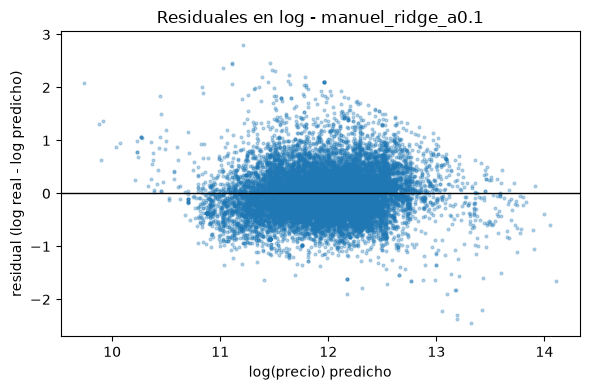

2026/11/06 15:51:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/06 15:51:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run manuel_mejor_lineal_artefactos at: http://3.82.57.253:8050/#/experiments/2/runs/4173e20e2757480a9faa0b60344d87fc
🧪 View experiment at: http://3.82.57.253:8050/#/experiments/2


,variable,coeficiente
12,cat__room_type_Shared room,-0.801767
10,cat__room_type_Hotel room,0.483649
9,cat__room_type_Entire home/apt,0.324096
24,bin__tiene_jacuzzi,0.243778
13,num__accommodates,0.229409
2,cat__neighbourhood_cleansed_Chapinero,0.222754
18,bin__is_shared_bathroom,-0.201182
8,cat__neighbourhood_cleansed_Usaquen,0.177634
3,cat__neighbourhood_cleansed_Engativa,-0.158554
20,bin__tiene_parqueadero,0.137939


,agrupacion,categoria,mdape,n
0,localidad,Barrios Unidos,22.056117,1026
8,localidad,Usaquen,23.634005,3366
5,localidad,Santa Fe,23.958997,1416
4,localidad,Fontibon,24.260309,992
7,localidad,Teusaquillo,24.734438,2781
3,localidad,Engativa,25.728655,1224
1,localidad,Candelaria,26.016510,724
2,localidad,Chapinero,26.783155,4842
6,localidad,Suba,27.310893,1190
9,room_type,Entire home/apt,23.077399,12802


In [ ]:
iniciar_mlflow('bogoprice-lineales')

res_lineales = pd.concat([pd.DataFrame(resultados), pd.DataFrame(resultados_enet)], ignore_index=True)
mejor = res_lineales.sort_values('mdape').iloc[0]['corrida']
pipe = pipelines[mejor]
modelo_mejor = pipe.named_steps['modelo']

pred_log = pipe.predict(X_test)
pred_cop = np.exp(pred_log)
residuales = test[config.TARGET_LOG].values - pred_log

# Anuncios de septiembre cuyo id no aparece en la captura completa de junio
ids_junio = set(pd.read_csv(config.ruta_captura('2026-06'), usecols=['id'])['id'])
es_nuevo = ~test['id'].isin(ids_junio).values

m = metricas_precio(y_test_cop, pred_cop)
m['mdape_nuevos'] = mdape(y_test_cop.values[es_nuevo], pred_cop[es_nuevo])
print(f"Mejor corrida lineal: {mejor} | anuncios nuevos: {es_nuevo.sum()} de {len(test)}")
print({k: round(v, 3) for k, v in m.items()})

# Coeficientes de mayor valor absoluto
coefs = pd.DataFrame({
    'variable': pipe.named_steps['prep'].get_feature_names_out(),
    'coeficiente': modelo_mejor.coef_,
})
top20 = coefs.reindex(coefs['coeficiente'].abs().sort_values(ascending=False).index).head(20)

# MdAPE por localidad y por room_type
ape = pd.DataFrame({
    'neighbourhood_cleansed': test['neighbourhood_cleansed'].values,
    'room_type': test['room_type'].values,
    'ape': np.abs(pred_cop - y_test_cop.values) / y_test_cop.values * 100,
})
por_grupo = pd.concat([
    ape.groupby('neighbourhood_cleansed')['ape'].agg(mdape='median', n='size').reset_index()
       .rename(columns={'neighbourhood_cleansed': 'categoria'}).assign(agrupacion='localidad'),
    ape.groupby('room_type')['ape'].agg(mdape='median', n='size').reset_index()
       .rename(columns={'room_type': 'categoria'}).assign(agrupacion='room_type'),
], ignore_index=True)[['agrupacion', 'categoria', 'mdape', 'n']]

params = {'corrida_origen': mejor, 'modelo': type(modelo_mejor).__name__,
          **{k: v for k, v in modelo_mejor.get_params().items() if k in ('alpha', 'l1_ratio')}}

with tempfile.TemporaryDirectory() as tmp:
    ruta_png = os.path.join(tmp, 'residuales_log.png')
    ruta_coef = os.path.join(tmp, 'coeficientes_top20.csv')
    ruta_grupos = os.path.join(tmp, 'mdape_por_grupo.csv')

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(pred_log, residuales, s=4, alpha=0.3)
    ax.axhline(0, color='black', lw=1)
    ax.set(xlabel='log(precio) predicho', ylabel='residual (log real - log predicho)',
           title=f'Residuales en log - {mejor}')
    fig.tight_layout()
    fig.savefig(ruta_png, dpi=120)
    plt.show()

    top20.to_csv(ruta_coef, index=False)
    por_grupo.to_csv(ruta_grupos, index=False)
    registrar_corrida('manuel_mejor_lineal_artefactos', params, m, pipeline=pipe,
                      artefactos=[ruta_png, ruta_coef, ruta_grupos])

display(top20)
display(por_grupo.sort_values(['agrupacion', 'mdape']))

### 1) Tabla resumen (ordenada por MdAPE)

| # | Corrida | Modelo | alpha | l1_ratio | MdAPE (%) | MAE (COP) | RMSE log |
|---|---|---|---|---|---|---|---|
| 1 | `Grupo6_ridge_a0.1` | Ridge | 0.1 | — | 25.0354 | 64,447.15 | 0.4321 |
| 2 | `Grupo6_ridge_a1` | Ridge | 1 | — | 25.0404 | 64,447.03 | 0.4321 |
| 3 | `Grupo6_enet_a0.001_l1_0.1` | ElasticNet | 0.001 | 0.1 | 25.0752 | 64,464.12 | 0.4322 |
| 4 | `Grupo6_ridge_a10` | Ridge | 10 | — | 25.1005 | 64,452.18 | 0.4321 |
| 5 | `Grupo6_enet_a0.01` | ElasticNet | 0.01 | 0.5 | 25.1689 | 64,988.41 | 0.4389 |
| 6 | `Grupo6_mediana_localidad_tipo` | Mediana | — | — | 29.5257 | 76,895.15 | 0.5168 |

**Mejora de la mejor corrida frente a la línea base:** 4.49 puntos porcentuales de MdAPE (de 29.53 % a 25.04 %) y $12,448 de MAE, es decir, 16.2 % menos.

**Tabla complementaria: selección de características (`bogoprice-lineales-features`) y línea base**

Las tres corridas del experimento usan Ridge con `alpha=0.1` y cambian solo el conjunto de variables. La línea base va como referencia.

| # | Corrida | Conjunto de variables | N.º de variables | MdAPE (%) | Diferencia de MdAPE frente a `completo` (puntos) | MAE (COP) | RMSE log |
|---|---|---|---|---|---|---|---|
| 1 | `Grupo6_ridge_a0.1_completo` | Completo (`config.FEATURES`) | 14 | 25.0354 | — | 64,447.15 | 0.4321 |
| 2 | `Grupo6_ridge_a0.1_sin_amenidades` | Sin amenidades (conserva `is_shared_bathroom`) | 8 | 25.6055 | +0.57 | 65,571.00 | 0.4399 |
| 3 | `Grupo6_ridge_a0.1_minimo` | Mínimo (localidad, `room_type`, `accommodates`, `minimum_nights`) | 4 | 25.9067 | +0.87 | 66,447.28 | 0.4446 |
| 4 | `Grupo6_mediana_localidad_tipo` (línea base) | Solo localidad y `room_type` | 2 | 29.5257 | +4.49 | 76,895.15 | 0.5168 |